# 12 · Cross-Attention Fusion

**The question:** How should the two kinds of information in a flow be combined? So far, all tokens are put into one sequence and every token looks
at every other (**self-attention**). Is it better to let the **flow measurements** explicitly ask questions of the **context** (recent-flow counters,
protocol, service, state) and the other way round (**cross-attention**)?

| | |
|---|---|
| **Input** | Scaled `total_and_byte44` inputs; network weighting from Notebook 10; convolution from Notebook 11 |
| **What we do** | Train the network with self-attention fusion and with cross-attention fusion, 3 seeds each |
| **Output** | A decision: keep cross-attention or not. Notebook 13 builds on the winner |

**Decision rule (same as Notebook 11):** keep the block only if it raises the 3-seed mean macro F1 and is better in at least 2 of the 3 seeds.

## 1. Setup

In [1]:
import sys
import warnings
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').is_dir())))
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from sklearn.metrics import f1_score

from src.notebook_helpers import TRAIN_CSV, RAW_SHA256, CLASSES, DATA, MODELS, sha256, save_table, save_figure, save_json, read_json, setup_style, write_leaderboard
from src.flow_networks import (FlowData, BASE_CONFIG, SelfAttentionFusion, CrossAttentionFusion, run_config, paired_comparison,
                               leaderboard_row, show_code, DEVICE, TEXT)
setup_style()
assert sha256(TRAIN_CSV) == RAW_SHA256['train']

WEIGHTING = read_json(MODELS / '10_rare_class_choice.json')['network_weighting']
SCALES = read_json(MODELS / '11_decision.json')['scales']
print(f'weighting: {WEIGHTING} | convolution scales: {SCALES} | device: {DEVICE}')
data = FlowData('total_and_byte44')

weighting: sqrt | convolution scales: [3, 5, 7] | device: cuda


## 2. Self-attention versus cross-attention

| | Self-attention (so far) | Cross-attention (new) |
|---|---|---|
| Tokens | one sequence: 28 flow + 13 context + 3 text tokens | two groups: **flow** (28) and **context** (13 + 3) |
| Who looks at whom | every token at every token | flow tokens look at context tokens, and context tokens look at flow tokens |
| Idea | let the model find any relation | force the model to relate *what this flow did* to *what was happening around it* |

In the reference paper, cross-branch fusion joins the network-flow stream and the DNS stream. Our two groups are the closest honest equivalent:
**per-flow measurements** versus **context** (counts over recent flows, protocol, service, state). It is **not** DNS data.

In [2]:
show_code(SelfAttentionFusion, CrossAttentionFusion)

```python
class SelfAttentionFusion(nn.Module):
    """Notebook 08 fusion: join both branches into one sequence and let every position attend to every other."""

    def __init__(self, channels=64, heads=4):
        super().__init__()
        self.attention = nn.MultiheadAttention(channels, heads, batch_first=True)
        self.norm = nn.LayerNorm(channels)

    def forward(self, a, b, text_tokens, return_attention=False):
        h = torch.cat([a, b, text_tokens], dim=1)
        mixed, weights = self.attention(h, h, h, need_weights=return_attention)
        return self.norm(h + mixed), weights

```

```python
class CrossAttentionFusion(nn.Module):
    """Cross-attention fusion: the flow-measurement tokens (branch A) ask questions of the context tokens
    (branch B + protocol/service/state), and the context tokens ask questions of the flow tokens.
    Each side keeps its own sequence and is enriched with the information of the other side."""

    def __init__(self, channels=64, heads=4):
        super().__init__()
        self.flow_asks_context = nn.MultiheadAttention(channels, heads, batch_first=True)
        self.context_asks_flow = nn.MultiheadAttention(channels, heads, batch_first=True)
        self.norm_flow, self.norm_context = nn.LayerNorm(channels), nn.LayerNorm(channels)

    def forward(self, a, b, text_tokens, return_attention=False):
        context = torch.cat([b, text_tokens], dim=1)
        flow_update, w_fc = self.flow_asks_context(a, context, context, need_weights=return_attention)
        context_update, w_cf = self.context_asks_flow(context, a, a, need_weights=return_attention)
        h = torch.cat([self.norm_flow(a + flow_update), self.norm_context(context + context_update)], dim=1)
        return h, (w_fc, w_cf)

```

## 3. Train both versions (3 seeds each)

In [3]:
SELF = dict(BASE_CONFIG, weighting=WEIGHTING, scales=SCALES, fusion='self')
CROSS = dict(BASE_CONFIG, weighting=WEIGHTING, scales=SCALES, fusion='cross')
self_runs, self_proba, _, _ = run_config(data, SELF, label='self-attention')
cross_runs, cross_proba, cross_models, _ = run_config(data, CROSS, label='cross-attention')

self-attention seed 42: model_selection macro F1 0.5928 | stopping macro F1 0.5932
self-attention seed 43: model_selection macro F1 0.5889 | stopping macro F1 0.5984


self-attention seed 44: model_selection macro F1 0.5975 | stopping macro F1 0.6009


cross-attention seed 42: model_selection macro F1 0.6054 | stopping macro F1 0.6177


cross-attention seed 43: model_selection macro F1 0.5978 | stopping macro F1 0.6066


cross-attention seed 44: model_selection macro F1 0.5831 | stopping macro F1 0.5812


## 4. Results

In [4]:
runs = pd.concat([self_runs, cross_runs], ignore_index=True)
save_table(runs, '12_runs')
display(runs[['experiment', 'seed', 'macro F1', 'accuracy', 'false-positive rate', 'Worms correct (of 13)', 'epochs', 'train minutes', 'parameters']])
display(runs.groupby('experiment', sort=False)['macro F1'].agg(['mean', 'std', 'min', 'max']))

y_eval = data.y['model_selection'].numpy()
comparison, overall = paired_comparison(y_eval, cross_proba, self_proba, 'cross-attention vs self-attention')
save_table(comparison, '12_comparison')
display(comparison)

per_class = pd.DataFrame({
    'self-attention F1': np.mean([f1_score(y_eval, p.argmax(1), average=None, labels=range(10), zero_division=0) for p in self_proba.values()], axis=0),
    'cross-attention F1': np.mean([f1_score(y_eval, p.argmax(1), average=None, labels=range(10), zero_division=0) for p in cross_proba.values()], axis=0),
}, index=CLASSES)
per_class['change'] = per_class.iloc[:, 1] - per_class.iloc[:, 0]
save_table(per_class, '12_per_class', index=True)
display(per_class.round(3))

,experiment,seed,macro F1,accuracy,false-positive rate,Worms correct (of 13),epochs,train minutes,parameters
0,self-attention,42,0.5928,0.7885,0.1905,7,40,1.7190,68872
1,self-attention,43,0.5889,0.7900,0.1880,6,35,1.5922,68872
2,self-attention,44,0.5975,0.7898,0.1941,7,39,1.6597,68872
3,cross-attention,42,0.6054,0.7939,0.1732,7,38,2.1216,85640
4,cross-attention,43,0.5978,0.7904,0.1809,8,35,1.9204,85640
5,cross-attention,44,0.5831,0.7911,0.1668,9,46,2.4518,85640


,mean,std,min,max
experiment,,,,
self-attention,0.5931,0.0043,0.5889,0.5975
cross-attention,0.5955,0.0113,0.5831,0.6054


,comparison,seed,difference,95% low,95% high,verdict
0,cross-attention vs self-attention,42,0.0126,0.0023,0.0229,first clearly better
1,cross-attention vs self-attention,43,0.0089,-0.0029,0.0216,could be chance
2,cross-attention vs self-attention,44,-0.0144,-0.0266,-0.0011,second clearly better


,self-attention F1,cross-attention F1,change
Analysis,0.2750,0.2680,-0.0060
Backdoor,0.2420,0.2310,-0.0110
DoS,0.4710,0.4780,0.0070
Exploits,0.6690,0.6620,-0.0070
Fuzzers,0.7130,0.7160,0.0040
Generic,0.9880,0.9880,0.0000
Normal,0.8920,0.8990,0.0080
Reconnaissance,0.8250,0.8250,-0.0000
Shellcode,0.5780,0.5860,0.0080
Worms,0.2780,0.3000,0.0210


**What we see:**

- **Cross-attention is very slightly better on average** (0.596 vs 0.593) and better for 2 of the 3 seeds, but again the seed tests disagree:
  clearly better for seed 42, chance for seed 43, clearly worse for seed 44. On macro F1 alone, the gain is not reliable.
- **Its clearer effect is fewer false alarms:** the false-positive rate drops for every seed (about 19% → 17%), and Worms detection rises slightly
  (6-7 → 7-9 of 13).
- It is somewhat bigger (86k vs 69k parameters) and slower to train (about 2.2 vs 1.7 minutes per run on the GPU).

## 5. What do the flow features ask the context?

For 3,000 `model_selection` flows we average the cross-attention weights of seed 42: each row is a flow feature, each column a context token.
A dark cell means "this flow feature mostly looked at that context token". This describes what the model uses, not what causes an attack.

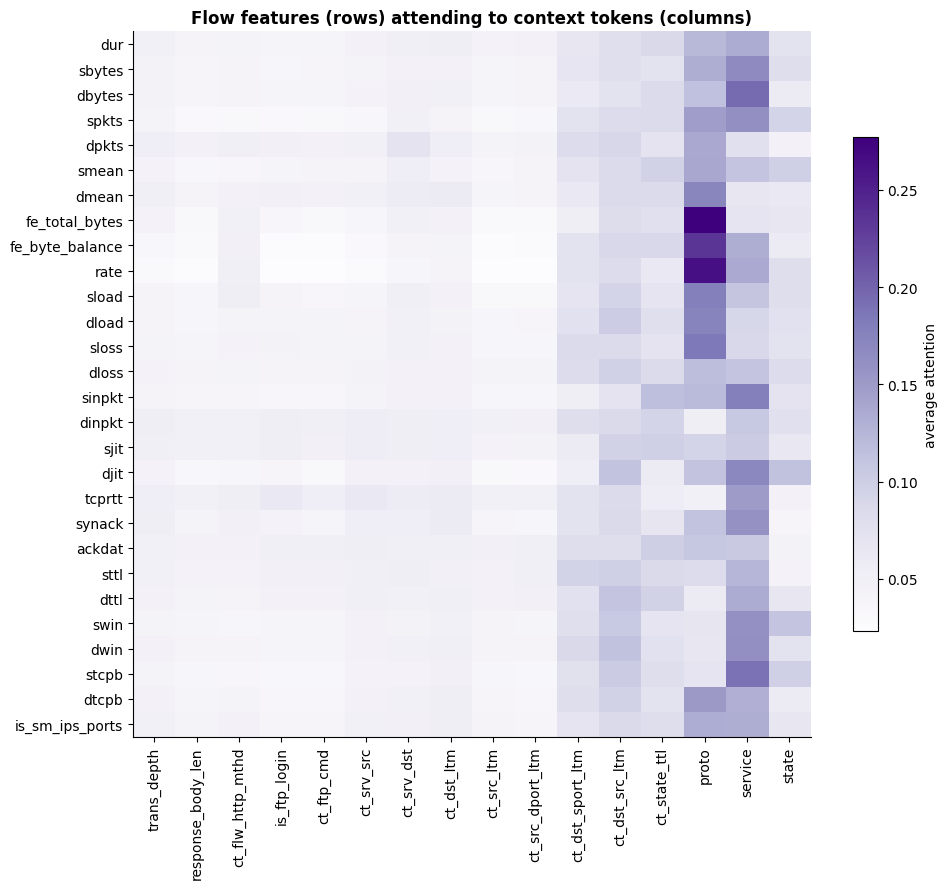

,proto,service,ct_dst_src_ltm,ct_state_ttl,ct_dst_sport_ltm,state
average attention received,0.1309,0.1303,0.0900,0.0807,0.0720,0.0711


In [5]:
model = cross_models[42]
model.eval()
sample = np.random.default_rng(1).choice(len(y_eval), 3000, replace=False)
with torch.no_grad():
    _, (flow_to_context, context_to_flow) = model(data.numbers['model_selection'][sample].to(DEVICE),
                                                  data.codes['model_selection'][sample].to(DEVICE), return_attention=True)
heat = pd.DataFrame(flow_to_context.mean(0).cpu().numpy(), index=data.branch_a, columns=data.branch_b + TEXT)
save_table(heat, '12_cross_attention_weights', index=True)

fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(heat, cmap='Purples', aspect='auto')
ax.set_xticks(range(heat.shape[1]), heat.columns, rotation=90); ax.set_yticks(range(heat.shape[0]), heat.index); ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.7, label='average attention')
ax.set_title('Flow features (rows) attending to context tokens (columns)')
plt.tight_layout(); save_figure(fig, '12_cross_attention'); plt.show()
display(heat.mean(axis=0).sort_values(ascending=False).head(6).rename('average attention received').to_frame().T)

**What we see:**

- The flow features look most at **protocol and service** (about 13% of attention each), then at three "recent flows" counters
  (`ct_dst_src_ltm`, `ct_state_ttl`, `ct_dst_sport_ltm`) and the connection state.
- So the network uses the context the way an analyst would: *what kind of connection is this* and *how many similar connections happened recently*.
- `ct_state_ttl` combines connection state with TTL, which Notebooks 03 and 06 already identified as a very strong (and possibly testbed-specific) signal.

## 6. Decision

In [6]:
wins = int(sum(cross_runs.set_index('seed')['macro F1'] > self_runs.set_index('seed')['macro F1']))
gain = cross_runs['macro F1'].mean() - self_runs['macro F1'].mean()
keep = bool(gain > 0 and wins >= 2)
decision = {'block': 'cross-attention fusion', 'mean gain': round(float(gain), 4), 'seeds where better': f'{wins} of 3',
            'bootstrap verdict over seeds': overall, 'kept': keep, 'fusion': 'cross' if keep else 'self', 'scales': SCALES}
save_json(decision, MODELS / '12_decision.json')
display(pd.Series(decision).to_frame('decision'))
write_leaderboard('12', [leaderboard_row(f'FlowNet self-attention, scales {SCALES} ({WEIGHTING})', self_runs),
                         leaderboard_row(f'FlowNet cross-attention, scales {SCALES} ({WEIGHTING})', cross_runs)])
assert sha256(TRAIN_CSV) == RAW_SHA256['train']

,decision
block,cross-attention fusion
mean gain,0.0024
seeds where better,2 of 3
bootstrap verdict over seeds,depends on the seed
kept,True
fusion,cross
scales,"[3, 5, 7]"


## Summary

### What we learned

| Question | Answer |
|---|---|
| Does cross-attention fusion help? | **Slightly, not reliably** on macro F1 (+0.002 mean, 2 of 3 seeds, seed tests disagree) |
| What does it clearly do? | **Fewer false alarms for every seed** (about 19% → 17%) and slightly more Worms found |
| What does the flow side look at? | Protocol, service and the recent-flow counters: the connection type and its context |
| Decision (by the fixed rule) | **Kept**: cross-attention fusion with scales 3, 5 and 7 |

### What is still uncertain

- Both blocks so far (multi-scale, cross-attention) passed the rule by small margins. The ablation study (Notebook 15) re-tests every part inside the final design.

### What comes next

**Notebook 13** tests the last block: TCN-BiLSTM.